<a href="https://colab.research.google.com/github/Insight-Sogang-Univ/insight-16th/blob/heeyeon/advanced/heeyeon/session08/%EC%82%AC%EC%A0%84%EA%B3%BC%EC%A0%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI 에이전트와 MCP 핵심 개념 정리

---

## 1. AI 에이전트란?

### 1-1. AI 에이전트의 정의
목표를 받으면 스스로 계획, 도구 사용하고, 결과를 확인하며 작업을 끝까지 수행하는 AI 시스템.

LLM이 두뇌 역할을 하고, 도구가 손발 역할을 하며, 메모리와 계획 기능이 이를 보완한다
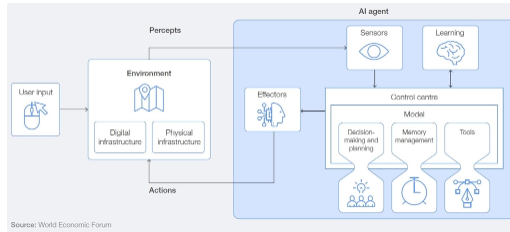



### 1-2. 생성형 AI vs 에이전틱 AI
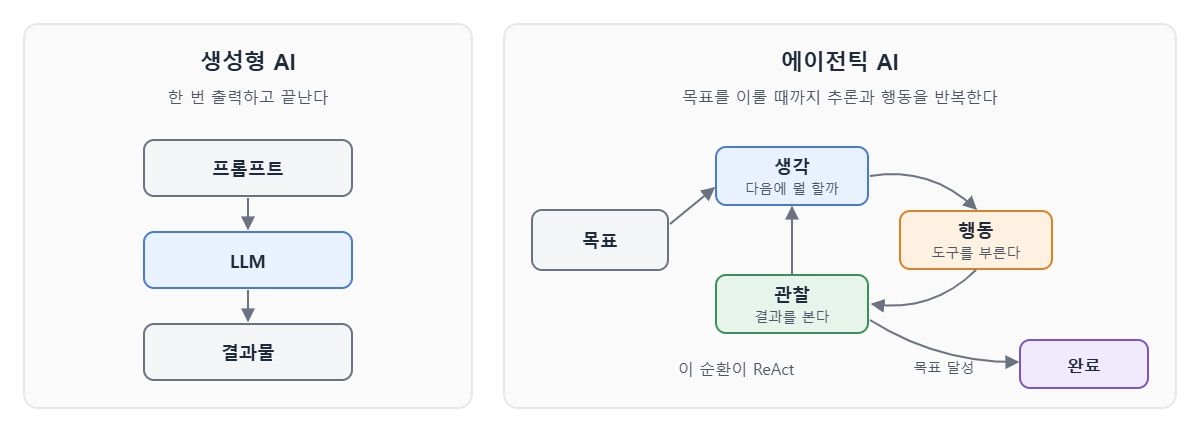

| 구분 | 생성형 AI | 에이전틱 AI |
|---|---|---|
| 동작 방식 | 질문 1번답변 1번 | 목표 → 여러 단계 반복 수행 |
| 역할 | 콘텐츠 생성 | 작업 수행 |
| 외부 연결 | 없음 | 도구·API·데이터 사용 |
| 주도권 | 사람이 매 단계 지시 | AI가 다음 행동을 스스로 결정 |

### 1-3. ReAct: 생각 → 행동 → 관찰


ReAct, 에이전틱 AI의 핵심 작동 방식
Reasoning(추론) + Acting(행동)
‘생각 → 행동 → 관찰 → 생각’ 의 순환 반복

 생각: 지금 무엇을 해야 할지 판단함    
 행동: 도구를 호출함   
 관찰: 도구 결과를 확인함   
- 목표를 달성할 때까지 이 순환을 반복
- 추론만 하는 방식보다 사실 확인이 가능하고 오류 수정이 쉬움

### 1-4. 다중 에이전트: 오케스트레이터 + 서브 에이전트

역할을 나누는 이유   

-> 스스로 실수를 잡기 어려움   
-> 동시에 여러 갈래를 조사하기 위해서   

오케스트레이터는 전체 작업을 쪼개고, 분배하고, 결과를 종합하는 관리자 역할. 서브 에이전트는 검색, 분석, 작성 등 한 가지 작업에 특화된 실무자 역할. 병렬 처리와 역할별 전문화가 가능 각 에이전트의 맥락 부담이 줄어들게한다... 반면 비용이 늘고 에이전트 간 정보 전달 과정에서 오류가 생긴다

---

## 2. MCP란?

- **세 역할: Host / Client / Server**
    
    
    | 역할 | 정체 | 하는 일 | 예시 |
    | --- | --- | --- | --- |
    | **Host** | 사용자가 쓰는 AI 앱 | LLM을 품고 클라이언트를 만들고 관리 / 어떤 서버·도구 호출을 허용할지 결정 | Claude, Cursor |
    | **Client** | 호스트 안의 통신 담당 | 서버 1개당 1개 → MCP 규격으로 메시지 전달만 | 서버 3개 → 클라이언트 3개 |
    | **Server** | 도구·데이터를 MCP 규격으로 내놓는 프로그램 | 가진 기능 선언 → 요청이 오면 실제 작업 수행 | 노션 서버, 깃허브 서버 |

### 2-1. 도구 호출의 원리: Function Calling
도구호주출은 LLM은 직접 실행하지 못하고, 어떤 함수를 어떤 인자로 부를지 텍스트로 출력만 한다. 실제 실행은 외부 프로그램이 담당하고, 그 결과를 다시 LLM에 전달하는 방식    


| 순서 | 주체 | 내용 |
|---|---|---|
| 1 | 프로그램 → LLM | 사용 가능한 도구 목록과 설명 제공 |
| 2 | LLM | 호출할 함수와 인자를 JSON으로 출력 |
| 3 | 프로그램 | 실제 함수 실행 |
| 4 | 프로그램 → LLM | 실행 결과 전달 |
| 5 | LLM | 결과를 바탕으로 최종 답변 생성 |

### 2-2. MCP가 필요한 이유:
MCP는 AI와 외부 도구를 연결하는 표준 규격, 표준이 없으면 AI 앱마다 도구별 연결을 따로 만들어야 하나 MCP 규격만 맞추면 도구를 한 번 만들어 여러 AI 앱에서 재사용 가능    



### 2-3. MCP의 구조: Host / Client / Server
| 구성 요소 | 역할 | 예시 |
|---|---|---|
| Host | 사용자가 쓰는 AI 애플리케이션 | Claude 앱, IDE |
| Client | Host 안에서 서버 1개와 1:1로 연결을 담당 | Host 내부 연결 모듈 |
| Server | 실제 기능과 데이터를 제공 | Notion, GitHub, DB 서버 |

### 2-4. MCP 서버의 기본 요소: Tools / Resources / Prompts
| 요소 | 의미 | 사용 결정 주체 |
|---|---|---|
| Tools | 검색, 파일 작성, 메일 발송 같은 실행 가능한 기능 | 모델 |
| Resources | 문서, 파일, DB 레코드 같은 읽기용 데이터 | 애플리케이션 |
| Prompts | 미리 만들어 둔 작업 템플릿 | 사용자 |

---

## 3. MCP의 한계

### 3-1. 보안 책임은 누구에게 있는가?
MCP는 연결 규격일 뿐 보안을 보장하지 않는다. 즉 서버를 만든 쪽, 서버를 설치한 사용자, Host 앱 사이의 책임 경계가 불분명해서

-> 권한 범위 설정, 인증, 실행 승인 절차를 각자 따로 챙겨야 하는 구조.

### 3-2. 도구 오염 / 프롬프트 주입
| 구분 | 도구 오염 | 프롬프트 주입 |
|---|---|---|
| 정의 | 도구 설명문에 악성 지시를 숨기는 공격 | 도구가 가져온 데이터 속 숨은 지시를 명령으로 착각하게 만드는 공격 |
| 악성 지시 위치 | 도구 설명문 | 웹페이지, 문서, 메일 등 외부 데이터 |
| 공격 시점 | 도구를 등록할 때 | 도구를 실행한 뒤 |

두 공격 모두 LLM이 지시와 데이터를 확실히 구분하지 못한다는 점에서 비롯됨. .

---

## 4. 데이터 구조화

한마디로 바닐라 rag의 한계, top k 딜레마 -> 그래프 구조가 필요

### 4-1. 왜 구조화가 필요한가?
에이전트가 정확히 작업하려면 데이터의 의미와 관계를 알아야 하기때문이다 비정형 데이터는 검색은 쉬워도 정확한 조회와 연결이 어려움.

-> 데이터를 구조화하면 정확도가 높아지고 환각이 줄며 권한 관리도 쉬워지는 장점이있다   

### 4-2. 그래프 구조와 팔란티어 온톨로지
- 그래프 구조: 데이터를 노드와 엣지로 표현함. 노드는 대상, 엣지는 관계를 뜻함
  예: 직원 —소속→ 부서, 고객 —구매→ 제품
- 온톨로지: 조직의 데이터를 현실 세계의 객체, 속성, 관계, 행동으로 정의한 공통 데이터 모델   
- 팔란티어 온톨로지는 흩어진 데이터를 고객, 공장, 주문 같은 비즈니스 객체로 통합
- 데이터 조회뿐 아니라/ 행동까지 정의해서 에이전트가 실제 업무를 실행 가능

---

## 5. XAI

### 5-1. 블랙박스가 왜 문제인가
결과는 나오지만 왜 그런 판단을 했는지 알 수 없다. 그래서 오류 원인 파악, 편향 탐지, 책임 소재 판단이 어렵다.   
-> 금융, 의료, 채용처럼 설명 의무가 있는 분야에서는 도입 장벽이 됨.

### 5-2. 기존 해결 시도들
| 방법 | 내용 | 한계 |
|---|---|---|
| SHAP | 각 입력 변수가 예측에 기여한 정도를 수치화 | 상관된 변수끼리 기여도 배분이 불안정 |
| LIME | 예측 주변을 단순 모델로 근사해 설명 | 설명이 실행할 때마다 달라질 수 있음 |
| Attention 시각화 | 모델이 입력의 어디에 주목했는지 표시 | 주목한 곳이 곧 판단 이유라는 보장 없음 |
| CoT | 모델이 추론 과정을 글로 작성 | 쓴 내용과 실제 내부 계산이 다를 수 있음 |

모두 모델 바깥에서 추정하는 방식이라 실제 내부 작동을 보여주지 못한다는 공통 한계가 있다    

shap lime attention cot

### 5-3. Mechanistic Interpretability
-모델 내부의 뉴런과 연결을 직접 분석해서 어떤 계산이 일어나는지 밝히는 연구 분야.
- 행동 관찰보다 뇌 회로 분석에 가까운 접근이며, 모델을 역설계해서 사람이 이해할 수 있는 알고리즘으로 설명하는 것이 목표

### 5-4. 핵심 개념 3가지
1. 특징 / Feature
   - 모델 내부에서 의미 있는 개념 하나를 나타내는 단위
   - 희소 오토인코더로 뉴런 활성에서 특징을 추출함
2. 중첩 / Superposition
   - 뉴런 수보다 훨씬 많은 개념을 겹쳐서 저장하는 현상임
  
3. 회로 / Circuit
   - 여러 특징이 연결되어 특정 작업을 수행하는 계산 경로
   (문장 속 앞 단어를 찾아 복사하는 회로, 다단계 추론 회로)
   - 회로를 찾으면 모델이 어떤 순서로 판단했는지 추적 가능해진다